In [12]:
from google.colab import auth
auth.authenticate_user()
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


from google.colab import auth
Imports Google's security tool so Colab can verify who is logged in.

auth.authenticate_user()
Triggers the pop-up that asks you to log into your Google account and grant permission to access your files.

from google.colab import drive
Imports the specific Drive tool for Colab.

drive.mount('/content/drive', force_remount=True)
Connects (mounts) the Google Drive to the Colab server. force_remount=True forces a fresh connection, which fixes the "credential propagation" error we got earlier.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load the data from the shared Google Drive
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# Quick clean to match Lawrence's Task 2.1
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm'])
df['Month'] = df['Date'].dt.month

for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.median()))
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))

df = df.drop(columns=['Month'])
print("Data loaded and cleaned. Shape:", df.shape)

/tmp/ipykernel_670/149740165.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df.groupby(['Location', 'Month'])[col].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else x))


Data loaded and cleaned. Shape: (142193, 20)


Imports: Loads pandas, numpy, matplotlib, seaborn, and sklearn for data analysis and scaling.

Loads Data: Reads weatherAUS.csv directly from the shared Drive folder.

Quick Clean:

Converts Date to a datetime format.

Drops rows with missing RainTomorrow.

Drops Evaporation, Sunshine, Cloud9am, and Cloud3pm (these are the columns with >35% missing data).

Uses a loop to fill remaining numeric missing values with the median (grouped by Location and Month) and categorical missing values with the mode.

Result: Prints the final shape of the cleaned datase

In [14]:
# Map compass points to angles and then to sine/cosine
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))

for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_angle'] = df[col].map(direction_map)
        df[col + '_sin'] = np.sin(np.radians(df[col + '_angle']))
        df[col + '_cos'] = np.cos(np.radians(df[col + '_angle']))
        df = df.drop(columns=[col, col + '_angle'])

# Map targets to 1/0
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# One-hot encode Location
df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)
print("Data transformed. Shape:", df_clean.shape)

Data transformed. Shape: (142193, 70)


**Purpose:**
This cell performs all the necessary data transformations for the EDA and modeling:
1. **Compass to Sine/Cosine:** Converts `WindGustDir`, `WindDir9am`, and `WindDir3pm` from 16 compass points into degrees, and then to sine and cosine values. This preserves the circular nature of the data (e.g., N and NNW stay close together).
2. **Target Encoding:** Maps `RainToday` and `RainTomorrow` from "Yes/No" strings to 1/0 integers.
3. **One-Hot Encoding:** Converts the `Location` text column into separate binary (0/1) columns for each station using `pd.get_dummies`, dropping the first column to avoid multicollinearity.
4. The original text columns are dropped to leave only numeric data for the models.

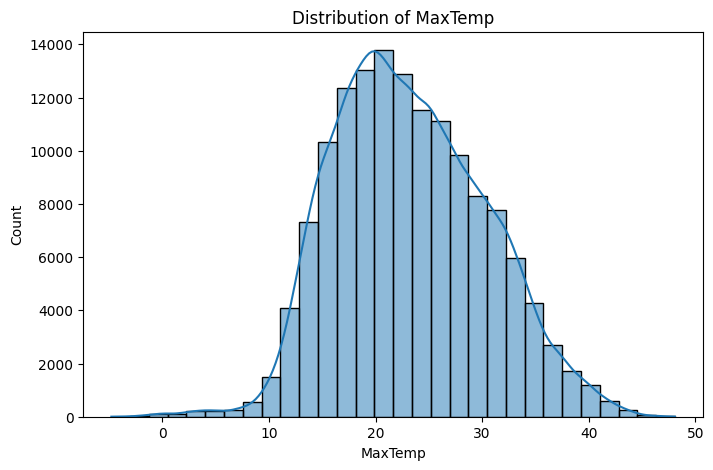

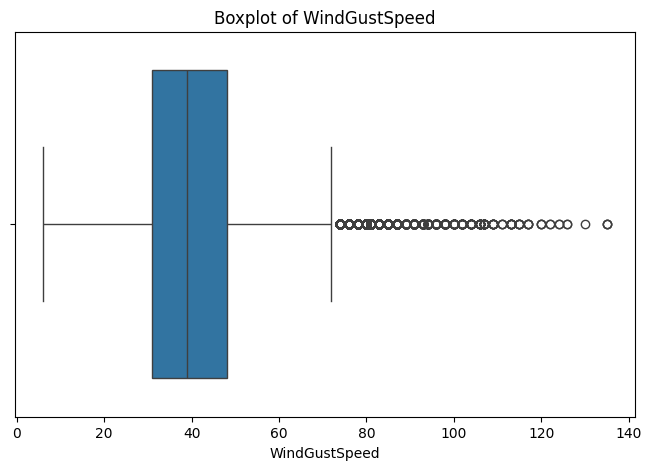

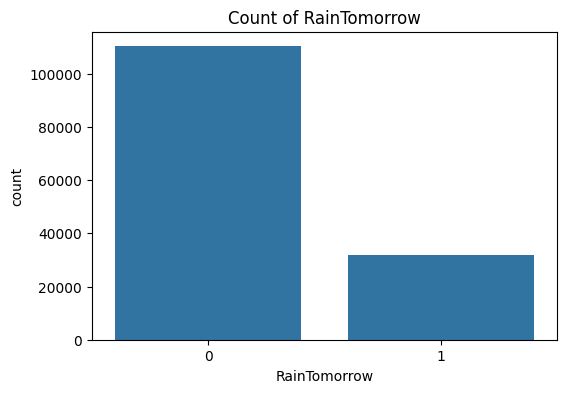

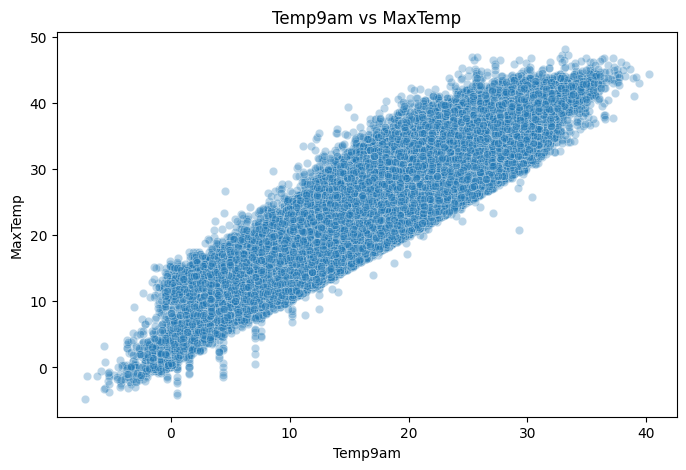

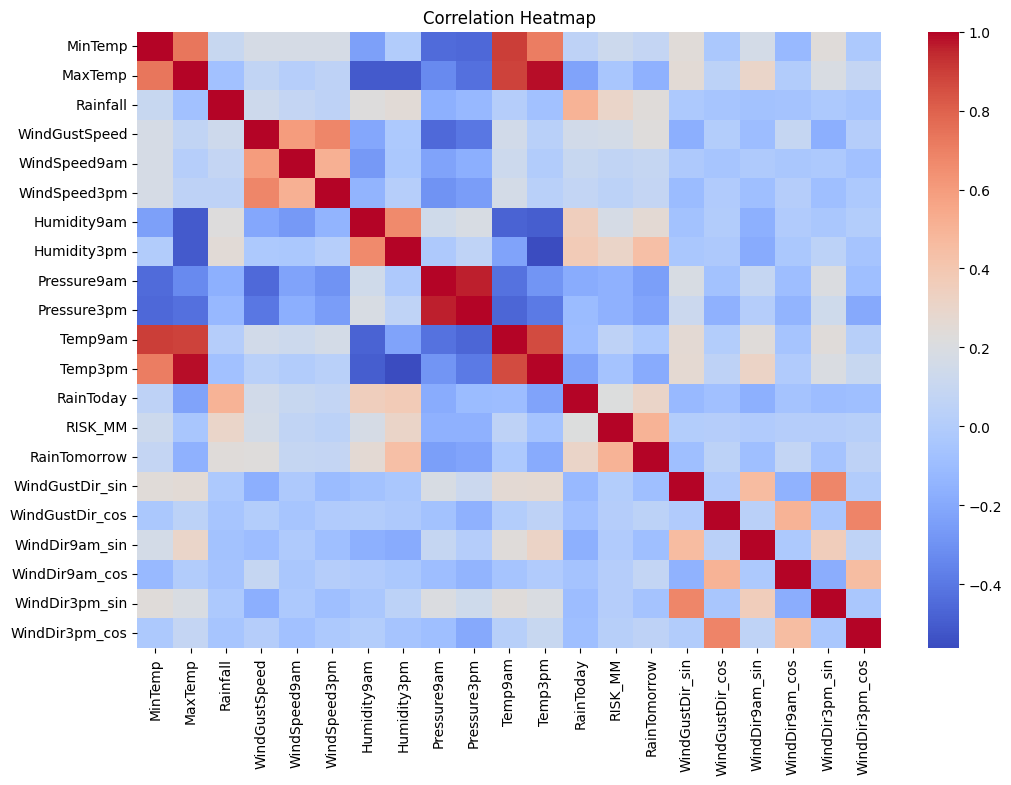

In [15]:
# 1. Histogram of MaxTemp
plt.figure(figsize=(8,5))
sns.histplot(df_clean['MaxTemp'], bins=30, kde=True)
plt.title('Distribution of MaxTemp')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/hist_target.png')
plt.show()

# 2. Box plot of WindGustSpeed
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['WindGustSpeed'])
plt.title('Boxplot of WindGustSpeed')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/box_feature.png')
plt.show()

# 3. Bar chart of RainTomorrow
plt.figure(figsize=(6,4))
sns.countplot(x='RainTomorrow', data=df_clean)
plt.title('Count of RainTomorrow')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/bar_class.png')
plt.show()

# 4. Scatter plot of Temp9am vs MaxTemp
plt.figure(figsize=(8,5))
sns.scatterplot(x='Temp9am', y='MaxTemp', data=df_clean, alpha=0.3)
plt.title('Temp9am vs MaxTemp')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/scatter_best.png')
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(12,8))
numeric_df = df_clean.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/corr_heatmap.png')
plt.show()

**Purpose:**
This cell generates and saves the five required exploratory data analysis (EDA) charts:
1. **Histogram (`hist_target.png`):** Shows the distribution and shape of the regression target (`MaxTemp`).
2. **Box Plot (`box_feature.png`):** Visualizes the spread and outliers of a key numeric feature (`WindGustSpeed`).
3. **Bar Chart (`bar_class.png`):** Shows the class imbalance of the classification target (`RainTomorrow`).
4. **Scatter Plot (`scatter_best.png`):** Plots `Temp9am` against `MaxTemp` to show their strong positive relationship.
5. **Heatmap (`corr_heatmap.png`):** Displays the correlation matrix for all numeric features to identify which variables are most strongly related to each other.

All charts are saved to the shared Google Drive `outputs` folder using `plt.savefig()`.

In [16]:
# Apply Min-Max and Standard Scaling to Humidity9am
min_max_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

original = df_clean['Humidity9am'].head(5).values
min_max_vals = min_max_scaler.fit_transform(df_clean[['Humidity9am']]).flatten()[:5]
standard_vals = standard_scaler.fit_transform(df_clean[['Humidity9am']]).flatten()[:5]

scaling_df = pd.DataFrame({
    'Original': original,
    'Min-Max': min_max_vals,
    'Standard': standard_vals
})
display(scaling_df)

,Original,Min-Max,Standard
0,71.0,0.71,0.107464
1,44.0,0.44,-1.311066
2,38.0,0.38,-1.626295
3,45.0,0.45,-1.258528
4,82.0,0.82,0.685384


**Purpose:**
This cell demonstrates the difference between Min-Max scaling and Standard scaling on the `Humidity9am` feature.
1. **MinMaxScaler:** Transforms the data so all values fall between 0 and 1.
2. **StandardScaler:** Transforms the data so it has a mean of 0 and a standard deviation of 1.
3. **Side-by-Side Comparison:** Shows the original values next to the min-max values and standardised values so we can visually see the mathematical transformation.

In [17]:
# Split by time: Train before 2015, Test 2015 onwards
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

# Separate features and target for MaxTemp prediction
features = [col for col in df_clean.columns if col not in ['MaxTemp', 'RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['MaxTemp']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

# Fit scaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Training set size: 98988
Test set size: 43205


**Purpose:**
This cell splits the data by time and scales the features to prevent data leakage.
1. **Time-Based Split:** We create a training set using dates before `2015-01-01` and a test set using dates from 2015 onwards. This prevents the model from learning from future weather patterns.
2. **Feature Selection:** We separate the target (`MaxTemp`) from the features, dropping `RainTomorrow` (because it's the other task's target) and `Date` (since we already split).
3. **Scaling (No Leakage):** We fit the `StandardScaler` only on `X_train`, and then apply that exact same transformation to `X_test`. This ensures the test set is treated as completely unseen future data.

**Task 2.2 Written Answer**

* **EDA Findings:**
  1. The histogram of MaxTemp shows a roughly normal distribution centered around 22°C, with a slight left skew.
  2. The correlation heatmap reveals a very strong positive correlation (dark red) between Temp9am and MaxTemp, confirming Temp9am as our best predictor.
  3. The countplot confirms a class imbalance in RainTomorrow: there are roughly 110,000 "No" days compared to 31,000 "Yes" days.
* **Scaling and Splitting:**
  The scaler must be fitted on the training data only to prevent data leakage. If we fit it on the whole dataset, the model would have access to the mean and variance of the future test set, which is cheating. A random split is wrong for weather records because it allows the model to see future weather during training. By splitting by time (before 2015 and after 2015), we simulate real-world forecasting where we only use the past to predict the future.